In [91]:
import numpy as np
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import time

In [92]:
import gymnasium as gym
env = gym.make("LunarLander-v3")

In [93]:
def epsilon_greedy(epsilon, Q_values, state):
    n = np.random.rand()
    if n < epsilon:
        action = np.random.choice([0, 1, 2, 3])
    else:
        if Q_values[(state, 0)] >= Q_values[(state, 1)] and Q_values[(state, 0)] >= Q_values[(state, 2)] and Q_values[(state, 0)] >= Q_values[(state, 3)]:
            action = 0
        elif Q_values[(state, 1)] > Q_values[(state, 0)] and Q_values[(state, 1)] > Q_values[(state, 2)] and Q_values[(state, 1)] >= Q_values[(state, 3)]:
            action = 1
        elif Q_values[(state, 2)] > Q_values[(state, 0)] and Q_values[(state, 2)] > Q_values[(state, 1)] and Q_values[(state, 2)] >= Q_values[(state, 3)]:
            action = 2
        else:
            action = 3
    return action

In [94]:
def epsilon_decay(epsilon, episode, min_epsilon = 0.01, decay_step = 0.05, decay_start = 0, decay_interval = 24):
    if episode > decay_start and (episode - decay_start) % decay_interval == 0:
        epsilon = np.round(max(min_epsilon, epsilon - decay_step), 2)
    return epsilon

In [95]:
def discretize_state(state):
    digitize_0 = np.linspace(-2.5, 2.5, 20)
    digitize_1 = np.linspace(-2.5, 2.5, 20)
    digitize_2 = np.linspace(-10, 10, 20)
    digitize_3 = np.linspace(-10, 10, 20)
    digitize_4 = np.linspace(-6.2831855, 6.2831855, 20)
    digitize_5 = np.linspace(-10, 10, 20)
    digitize_6 = np.linspace(-0.0, 1, 20)
    digitize_7 = np.linspace(-0.0, 1, 20)
    state_0 = np.digitize(state[0], digitize_0) - 1
    state_1 = np.digitize(state[1], digitize_1) - 1
    state_2 = np.digitize(state[2], digitize_2) - 1
    state_3 = np.digitize(state[3], digitize_3) - 1
    state_4 = np.digitize(state[4], digitize_4) - 1
    state_5 = np.digitize(state[5], digitize_5) - 1
    state_6 = np.digitize(state[6], digitize_6) - 1
    state_7 = np.digitize(state[7], digitize_7) - 1
    return (state_0, state_1, state_2, state_3, state_4, state_5, state_6, state_7)

In [96]:
def generate_episode(policy, epsilon, Q_values):
    episode = []
    state, _ = env.reset()
    done = False
    index = 0
    while not done:
        state = discretize_state(state)
        action = epsilon_greedy(epsilon, Q_values, state)
        next_state, reward, done, truncated, info = env.step(action)
        episode.append((state, action, reward))
        state = next_state
        if index == 500:
            break
        index += 1
    return episode

In [97]:
def SARSA_lambda(alpha, gamma, epsilon, lambda_, num_epi):
    Q_values = defaultdict(lambda : 0)
    E_values = defaultdict(lambda : 0)
    episodes = []
    for e in range(num_epi):
        print('Episode:', e + 1, ', Epsilon:', epsilon)
        episode = generate_episode(epsilon_greedy, epsilon, Q_values)
        for index, (state, action, reward) in enumerate(episode):
            if index == len(episode) - 1:
                break
            next_state, next_action, _ = episode[index + 1]
            td_error = reward + (gamma * Q_values[(next_state, next_action)]) - Q_values[(state, action)]
            E_values[(state, action)] += 1
            for (state, action, _) in episode:
                Q_values[(state, action)] += alpha * td_error * E_values[(state, action)]
                E_values[(state, action)] = gamma * lambda_ * E_values[(state, action)]
        epsilon = epsilon_decay(epsilon, e)
        episodes.append(episode)
    return episodes, Q_values

In [98]:
def episode_return(episodes):
    epi_returns = []
    for e in episodes:
        epi_return = 0
        i = 0
        for _, _, reward in e:
            epi_return += (0.95 ** i) * reward
            i += 1
        epi_returns.append(epi_return)
    return epi_returns

In [99]:
def simulate(Q_values):
    curr = time.time()
    state, _ = env.reset()
    state = discretize_state(state)
    action = epsilon_greedy(0, Q_values, state)
    done = False
    while not done:
        next_state, _, done, truncated, _ = env.step(action)
        next_state = discretize_state(next_state)
        next_action = epsilon_greedy(0, Q_values, next_state)
        action = next_action
    end = time.time()
    print('Time taken to finish episode using learned policy:', end - curr, 'seconds')

In [100]:
episodes, Q_values = SARSA_lambda(0.1, 0.95, 1, 0.8, 2000)

Episode: 1 , Epsilon: 1
Episode: 2 , Epsilon: 1
Episode: 3 , Epsilon: 1
Episode: 4 , Epsilon: 1
Episode: 5 , Epsilon: 1
Episode: 6 , Epsilon: 1
Episode: 7 , Epsilon: 1
Episode: 8 , Epsilon: 1
Episode: 9 , Epsilon: 1
Episode: 10 , Epsilon: 1
Episode: 11 , Epsilon: 1
Episode: 12 , Epsilon: 1
Episode: 13 , Epsilon: 1
Episode: 14 , Epsilon: 1
Episode: 15 , Epsilon: 1
Episode: 16 , Epsilon: 1
Episode: 17 , Epsilon: 1
Episode: 18 , Epsilon: 1
Episode: 19 , Epsilon: 1
Episode: 20 , Epsilon: 1
Episode: 21 , Epsilon: 1
Episode: 22 , Epsilon: 1
Episode: 23 , Epsilon: 1
Episode: 24 , Epsilon: 1
Episode: 25 , Epsilon: 1
Episode: 26 , Epsilon: 0.95
Episode: 27 , Epsilon: 0.95
Episode: 28 , Epsilon: 0.95
Episode: 29 , Epsilon: 0.95
Episode: 30 , Epsilon: 0.95
Episode: 31 , Epsilon: 0.95
Episode: 32 , Epsilon: 0.95
Episode: 33 , Epsilon: 0.95
Episode: 34 , Epsilon: 0.95
Episode: 35 , Epsilon: 0.95
Episode: 36 , Epsilon: 0.95
Episode: 37 , Epsilon: 0.95
Episode: 38 , Epsilon: 0.95
Episode: 39 , Epsilo

Episode: 295 , Epsilon: 0.4
Episode: 296 , Epsilon: 0.4
Episode: 297 , Epsilon: 0.4
Episode: 298 , Epsilon: 0.4
Episode: 299 , Epsilon: 0.4
Episode: 300 , Epsilon: 0.4
Episode: 301 , Epsilon: 0.4
Episode: 302 , Epsilon: 0.4
Episode: 303 , Epsilon: 0.4
Episode: 304 , Epsilon: 0.4
Episode: 305 , Epsilon: 0.4
Episode: 306 , Epsilon: 0.4
Episode: 307 , Epsilon: 0.4
Episode: 308 , Epsilon: 0.4
Episode: 309 , Epsilon: 0.4
Episode: 310 , Epsilon: 0.4
Episode: 311 , Epsilon: 0.4
Episode: 312 , Epsilon: 0.4
Episode: 313 , Epsilon: 0.4
Episode: 314 , Epsilon: 0.35
Episode: 315 , Epsilon: 0.35
Episode: 316 , Epsilon: 0.35
Episode: 317 , Epsilon: 0.35
Episode: 318 , Epsilon: 0.35
Episode: 319 , Epsilon: 0.35
Episode: 320 , Epsilon: 0.35
Episode: 321 , Epsilon: 0.35
Episode: 322 , Epsilon: 0.35
Episode: 323 , Epsilon: 0.35
Episode: 324 , Epsilon: 0.35
Episode: 325 , Epsilon: 0.35
Episode: 326 , Epsilon: 0.35
Episode: 327 , Epsilon: 0.35
Episode: 328 , Epsilon: 0.35
Episode: 329 , Epsilon: 0.35
Epis

Episode: 583 , Epsilon: 0.01
Episode: 584 , Epsilon: 0.01
Episode: 585 , Epsilon: 0.01
Episode: 586 , Epsilon: 0.01
Episode: 587 , Epsilon: 0.01
Episode: 588 , Epsilon: 0.01
Episode: 589 , Epsilon: 0.01
Episode: 590 , Epsilon: 0.01
Episode: 591 , Epsilon: 0.01
Episode: 592 , Epsilon: 0.01
Episode: 593 , Epsilon: 0.01
Episode: 594 , Epsilon: 0.01
Episode: 595 , Epsilon: 0.01
Episode: 596 , Epsilon: 0.01
Episode: 597 , Epsilon: 0.01
Episode: 598 , Epsilon: 0.01
Episode: 599 , Epsilon: 0.01
Episode: 600 , Epsilon: 0.01
Episode: 601 , Epsilon: 0.01
Episode: 602 , Epsilon: 0.01
Episode: 603 , Epsilon: 0.01
Episode: 604 , Epsilon: 0.01
Episode: 605 , Epsilon: 0.01
Episode: 606 , Epsilon: 0.01
Episode: 607 , Epsilon: 0.01
Episode: 608 , Epsilon: 0.01
Episode: 609 , Epsilon: 0.01
Episode: 610 , Epsilon: 0.01
Episode: 611 , Epsilon: 0.01
Episode: 612 , Epsilon: 0.01
Episode: 613 , Epsilon: 0.01
Episode: 614 , Epsilon: 0.01
Episode: 615 , Epsilon: 0.01
Episode: 616 , Epsilon: 0.01
Episode: 617 ,

Episode: 867 , Epsilon: 0.01
Episode: 868 , Epsilon: 0.01
Episode: 869 , Epsilon: 0.01
Episode: 870 , Epsilon: 0.01
Episode: 871 , Epsilon: 0.01
Episode: 872 , Epsilon: 0.01
Episode: 873 , Epsilon: 0.01
Episode: 874 , Epsilon: 0.01
Episode: 875 , Epsilon: 0.01
Episode: 876 , Epsilon: 0.01
Episode: 877 , Epsilon: 0.01
Episode: 878 , Epsilon: 0.01
Episode: 879 , Epsilon: 0.01
Episode: 880 , Epsilon: 0.01
Episode: 881 , Epsilon: 0.01
Episode: 882 , Epsilon: 0.01
Episode: 883 , Epsilon: 0.01
Episode: 884 , Epsilon: 0.01
Episode: 885 , Epsilon: 0.01
Episode: 886 , Epsilon: 0.01
Episode: 887 , Epsilon: 0.01
Episode: 888 , Epsilon: 0.01
Episode: 889 , Epsilon: 0.01
Episode: 890 , Epsilon: 0.01
Episode: 891 , Epsilon: 0.01
Episode: 892 , Epsilon: 0.01
Episode: 893 , Epsilon: 0.01
Episode: 894 , Epsilon: 0.01
Episode: 895 , Epsilon: 0.01
Episode: 896 , Epsilon: 0.01
Episode: 897 , Epsilon: 0.01
Episode: 898 , Epsilon: 0.01
Episode: 899 , Epsilon: 0.01
Episode: 900 , Epsilon: 0.01
Episode: 901 ,

Episode: 1145 , Epsilon: 0.01
Episode: 1146 , Epsilon: 0.01
Episode: 1147 , Epsilon: 0.01
Episode: 1148 , Epsilon: 0.01
Episode: 1149 , Epsilon: 0.01
Episode: 1150 , Epsilon: 0.01
Episode: 1151 , Epsilon: 0.01
Episode: 1152 , Epsilon: 0.01
Episode: 1153 , Epsilon: 0.01
Episode: 1154 , Epsilon: 0.01
Episode: 1155 , Epsilon: 0.01
Episode: 1156 , Epsilon: 0.01
Episode: 1157 , Epsilon: 0.01
Episode: 1158 , Epsilon: 0.01
Episode: 1159 , Epsilon: 0.01
Episode: 1160 , Epsilon: 0.01
Episode: 1161 , Epsilon: 0.01
Episode: 1162 , Epsilon: 0.01
Episode: 1163 , Epsilon: 0.01
Episode: 1164 , Epsilon: 0.01
Episode: 1165 , Epsilon: 0.01
Episode: 1166 , Epsilon: 0.01
Episode: 1167 , Epsilon: 0.01
Episode: 1168 , Epsilon: 0.01
Episode: 1169 , Epsilon: 0.01
Episode: 1170 , Epsilon: 0.01
Episode: 1171 , Epsilon: 0.01
Episode: 1172 , Epsilon: 0.01
Episode: 1173 , Epsilon: 0.01
Episode: 1174 , Epsilon: 0.01
Episode: 1175 , Epsilon: 0.01
Episode: 1176 , Epsilon: 0.01
Episode: 1177 , Epsilon: 0.01
Episode: 1

Episode: 1421 , Epsilon: 0.01
Episode: 1422 , Epsilon: 0.01
Episode: 1423 , Epsilon: 0.01
Episode: 1424 , Epsilon: 0.01
Episode: 1425 , Epsilon: 0.01
Episode: 1426 , Epsilon: 0.01
Episode: 1427 , Epsilon: 0.01
Episode: 1428 , Epsilon: 0.01
Episode: 1429 , Epsilon: 0.01
Episode: 1430 , Epsilon: 0.01
Episode: 1431 , Epsilon: 0.01
Episode: 1432 , Epsilon: 0.01
Episode: 1433 , Epsilon: 0.01
Episode: 1434 , Epsilon: 0.01
Episode: 1435 , Epsilon: 0.01
Episode: 1436 , Epsilon: 0.01
Episode: 1437 , Epsilon: 0.01
Episode: 1438 , Epsilon: 0.01
Episode: 1439 , Epsilon: 0.01
Episode: 1440 , Epsilon: 0.01
Episode: 1441 , Epsilon: 0.01
Episode: 1442 , Epsilon: 0.01
Episode: 1443 , Epsilon: 0.01
Episode: 1444 , Epsilon: 0.01
Episode: 1445 , Epsilon: 0.01
Episode: 1446 , Epsilon: 0.01
Episode: 1447 , Epsilon: 0.01
Episode: 1448 , Epsilon: 0.01
Episode: 1449 , Epsilon: 0.01
Episode: 1450 , Epsilon: 0.01
Episode: 1451 , Epsilon: 0.01
Episode: 1452 , Epsilon: 0.01
Episode: 1453 , Epsilon: 0.01
Episode: 1

Episode: 1694 , Epsilon: 0.01
Episode: 1695 , Epsilon: 0.01
Episode: 1696 , Epsilon: 0.01
Episode: 1697 , Epsilon: 0.01
Episode: 1698 , Epsilon: 0.01
Episode: 1699 , Epsilon: 0.01
Episode: 1700 , Epsilon: 0.01
Episode: 1701 , Epsilon: 0.01
Episode: 1702 , Epsilon: 0.01
Episode: 1703 , Epsilon: 0.01
Episode: 1704 , Epsilon: 0.01
Episode: 1705 , Epsilon: 0.01
Episode: 1706 , Epsilon: 0.01
Episode: 1707 , Epsilon: 0.01
Episode: 1708 , Epsilon: 0.01
Episode: 1709 , Epsilon: 0.01
Episode: 1710 , Epsilon: 0.01
Episode: 1711 , Epsilon: 0.01
Episode: 1712 , Epsilon: 0.01
Episode: 1713 , Epsilon: 0.01
Episode: 1714 , Epsilon: 0.01
Episode: 1715 , Epsilon: 0.01
Episode: 1716 , Epsilon: 0.01
Episode: 1717 , Epsilon: 0.01
Episode: 1718 , Epsilon: 0.01
Episode: 1719 , Epsilon: 0.01
Episode: 1720 , Epsilon: 0.01
Episode: 1721 , Epsilon: 0.01
Episode: 1722 , Epsilon: 0.01
Episode: 1723 , Epsilon: 0.01
Episode: 1724 , Epsilon: 0.01
Episode: 1725 , Epsilon: 0.01
Episode: 1726 , Epsilon: 0.01
Episode: 1

Episode: 1968 , Epsilon: 0.01
Episode: 1969 , Epsilon: 0.01
Episode: 1970 , Epsilon: 0.01
Episode: 1971 , Epsilon: 0.01
Episode: 1972 , Epsilon: 0.01
Episode: 1973 , Epsilon: 0.01
Episode: 1974 , Epsilon: 0.01
Episode: 1975 , Epsilon: 0.01
Episode: 1976 , Epsilon: 0.01
Episode: 1977 , Epsilon: 0.01
Episode: 1978 , Epsilon: 0.01
Episode: 1979 , Epsilon: 0.01
Episode: 1980 , Epsilon: 0.01
Episode: 1981 , Epsilon: 0.01
Episode: 1982 , Epsilon: 0.01
Episode: 1983 , Epsilon: 0.01
Episode: 1984 , Epsilon: 0.01
Episode: 1985 , Epsilon: 0.01
Episode: 1986 , Epsilon: 0.01
Episode: 1987 , Epsilon: 0.01
Episode: 1988 , Epsilon: 0.01
Episode: 1989 , Epsilon: 0.01
Episode: 1990 , Epsilon: 0.01
Episode: 1991 , Epsilon: 0.01
Episode: 1992 , Epsilon: 0.01
Episode: 1993 , Epsilon: 0.01
Episode: 1994 , Epsilon: 0.01
Episode: 1995 , Epsilon: 0.01
Episode: 1996 , Epsilon: 0.01
Episode: 1997 , Epsilon: 0.01
Episode: 1998 , Epsilon: 0.01
Episode: 1999 , Epsilon: 0.01
Episode: 2000 , Epsilon: 0.01


In [101]:
total_returns = episode_return(episodes)

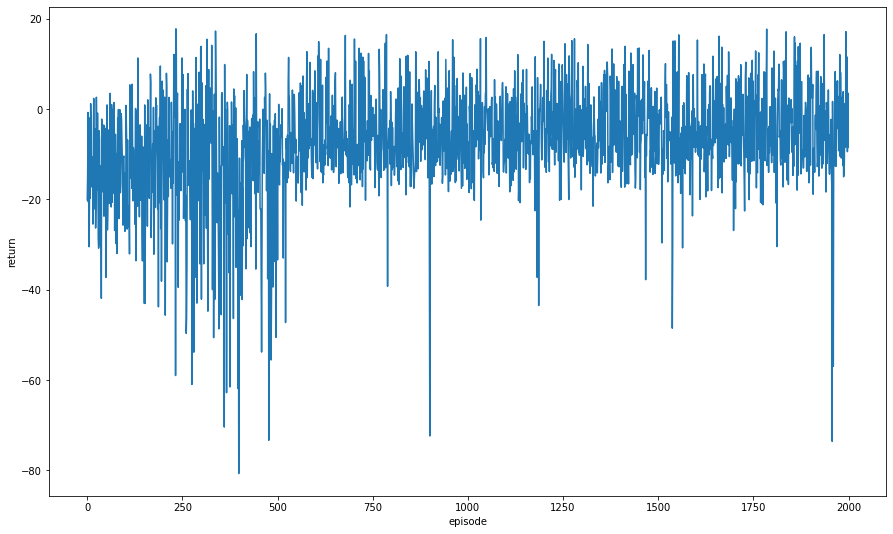

In [102]:
plt.figure(figsize = (15, 9))
plt.plot(total_returns)
plt.xlabel('episode')
plt.ylabel('return')
plt.show()

In [109]:
simulate(Q_values)

Time taken to finish episode using learned policy: 0.03877568244934082 seconds


In [110]:
len(episodes[0]), len(episodes[500]), len(episodes[1999])

(103, 126, 124)